In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [2]:
df = pd.read_csv("../data/analytical_dataset.csv")

df.head()

,id_student,code_module,code_presentation,gender,age_band,imd_band,num_of_prev_attempts,studied_credits,disability,final_result,total_clicks,active_days,unique_resources,avg_clicks_per_active_day,q1_active,q2_active,q3_active,q4_active,q1_clicks,q2_clicks,q3_clicks,q4_clicks,assessments_completed,average_assessment_score
0,11391,AAA,2013J,M,55<=,90-100%,0,240,N,Pass,934,40,55,23.35,1,1,1,1,545,165,38,186,5,82.0
1,28400,AAA,2013J,F,35-55,20-30%,0,60,N,Pass,1435,80,84,17.94,1,1,1,1,723,263,322,127,5,66.4
2,30268,AAA,2013J,F,35-55,30-40%,0,60,Y,Withdrawn,281,12,22,23.42,1,0,0,0,281,0,0,0,0,0.0
3,31604,AAA,2013J,F,35-55,50-60%,0,60,N,Pass,2158,123,82,17.54,1,1,1,1,879,503,457,319,5,76.0
4,32885,AAA,2013J,F,0-35,50-60%,0,60,N,Pass,1034,70,66,14.77,1,1,1,1,608,191,108,127,5,54.4


In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 32593
Columns: 24


In [4]:
df.isnull().sum()

id_student                      0
code_module                     0
code_presentation               0
gender                          0
age_band                        0
imd_band                     1111
num_of_prev_attempts            0
studied_credits                 0
disability                      0
final_result                    0
total_clicks                    0
active_days                     0
unique_resources                0
avg_clicks_per_active_day       0
q1_active                       0
q2_active                       0
q3_active                       0
q4_active                       0
q1_clicks                       0
q2_clicks                       0
q3_clicks                       0
q4_clicks                       0
assessments_completed           0
average_assessment_score        0
dtype: int64

In [5]:
df.duplicated(
    subset=["id_student", "code_module", "code_presentation"]
).sum()

np.int64(0)

In [6]:
outcome_counts = df["final_result"].value_counts()

print(outcome_counts)

final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64


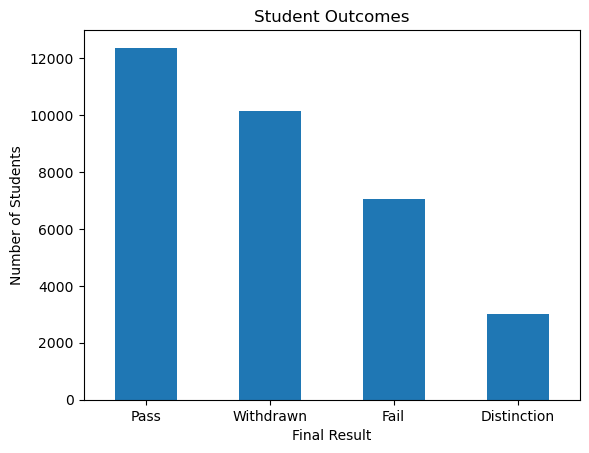

In [7]:
outcome_counts.plot(kind="bar")

plt.title("Student Outcomes")
plt.xlabel("Final Result")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()

In [8]:
engagement_by_outcome = (
    df.groupby("final_result")
      [["total_clicks", "active_days", "unique_resources",
        "avg_clicks_per_active_day"]]
      .mean()
      .round(2)
)

engagement_by_outcome

,total_clicks,active_days,unique_resources,avg_clicks_per_active_day
final_result,,,,
Distinction,2666.76,110.04,102.45,21.94
Fail,651.85,33.18,43.08,16.29
Pass,1921.81,87.04,89.06,20.46
Withdrawn,313.95,16.29,24.23,12.05


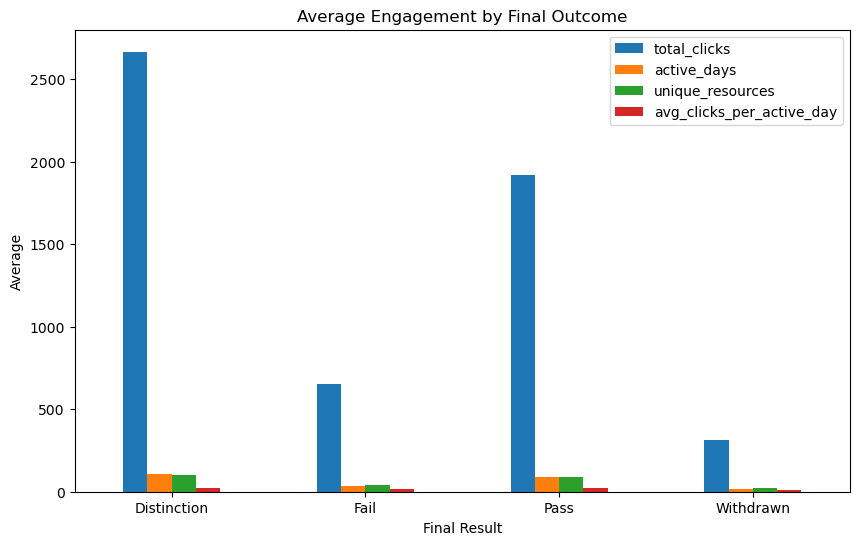

In [9]:
engagement_by_outcome.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Average Engagement by Final Outcome")
plt.xlabel("Final Result")
plt.ylabel("Average")
plt.xticks(rotation=0)
plt.legend()
plt.show()

In [10]:
retention = (
    df.groupby("final_result")
      [["q1_active", "q2_active", "q3_active", "q4_active"]]
      .mean()
      * 100
)

retention

,q1_active,q2_active,q3_active,q4_active
final_result,,,,
Distinction,99.801587,99.702381,99.933862,99.768519
Fail,94.044243,68.150879,50.865003,36.542825
Pass,99.684492,99.611682,99.668312,99.360893
Withdrawn,70.372194,29.962584,14.060654,3.958251


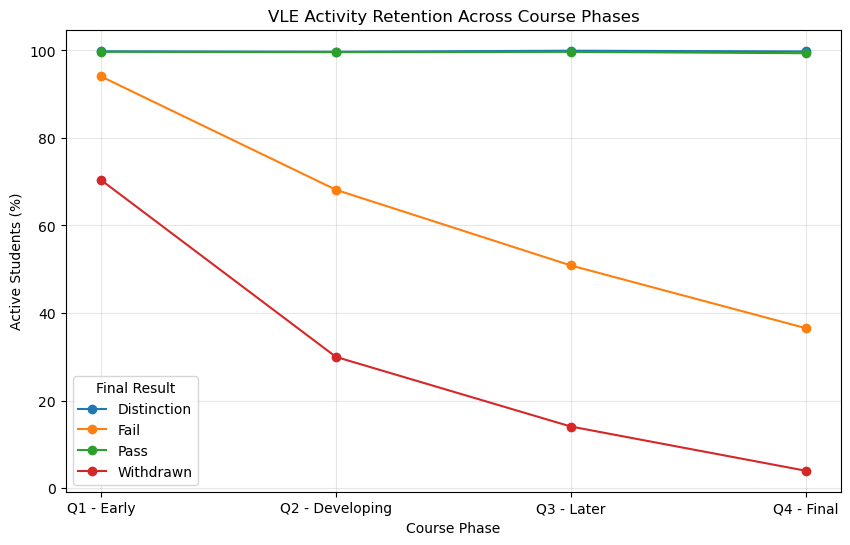

In [11]:
retention.T.plot(
    marker="o",
    figsize=(10, 6)
)

plt.title("VLE Activity Retention Across Course Phases")
plt.xlabel("Course Phase")
plt.ylabel("Active Students (%)")
plt.xticks(
    range(4),
    ["Q1 - Early", "Q2 - Developing", "Q3 - Later", "Q4 - Final"]
)
plt.legend(title="Final Result")
plt.grid(alpha=0.3)
plt.show()

In [12]:
assessment_by_outcome = (
    df.groupby("final_result")
      [["average_assessment_score", "assessments_completed"]]
      .mean()
      .round(2)
)

assessment_by_outcome

,average_assessment_score,assessments_completed
final_result,,
Distinction,88.49,8.71
Fail,52.51,4.04
Pass,76.16,8.58
Withdrawn,29.50,1.29


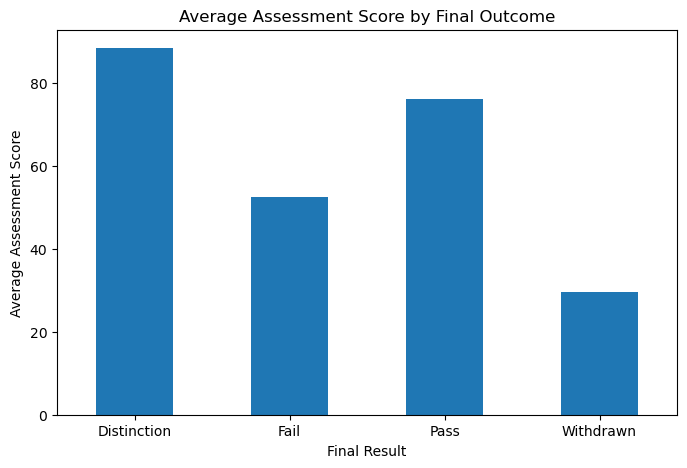

In [13]:
assessment_by_outcome["average_assessment_score"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Assessment Score by Final Outcome")
plt.xlabel("Final Result")
plt.ylabel("Average Assessment Score")
plt.xticks(rotation=0)
plt.show()

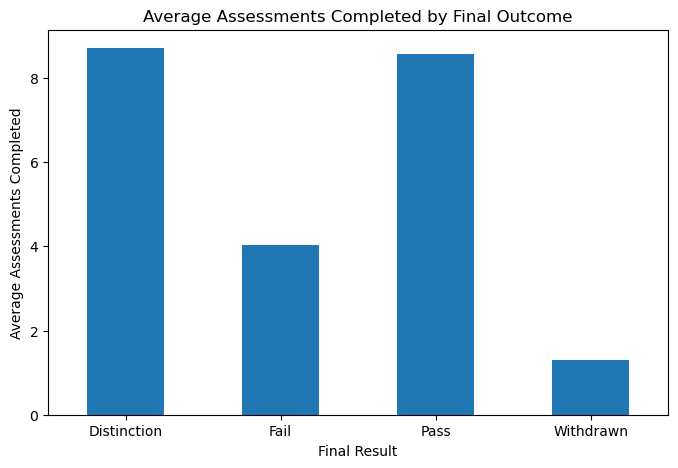

In [14]:
assessment_by_outcome["assessments_completed"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Assessments Completed by Final Outcome")
plt.xlabel("Final Result")
plt.ylabel("Average Assessments Completed")
plt.xticks(rotation=0)
plt.show()

In [15]:
# Early disengagement:
# Active in Q1 but inactive in Q2

df["early_disengagement"] = (
    (df["q1_active"] == 1) &
    (df["q2_active"] == 0)
).astype(int)

early_disengagement_rate = (
    df.groupby("final_result")["early_disengagement"]
      .mean()
      .mul(100)
      .round(2)
      .sort_values(ascending=False)
)

early_disengagement_rate

final_result
Withdrawn      40.56
Fail           26.42
Pass            0.31
Distinction     0.23
Name: early_disengagement, dtype: float64

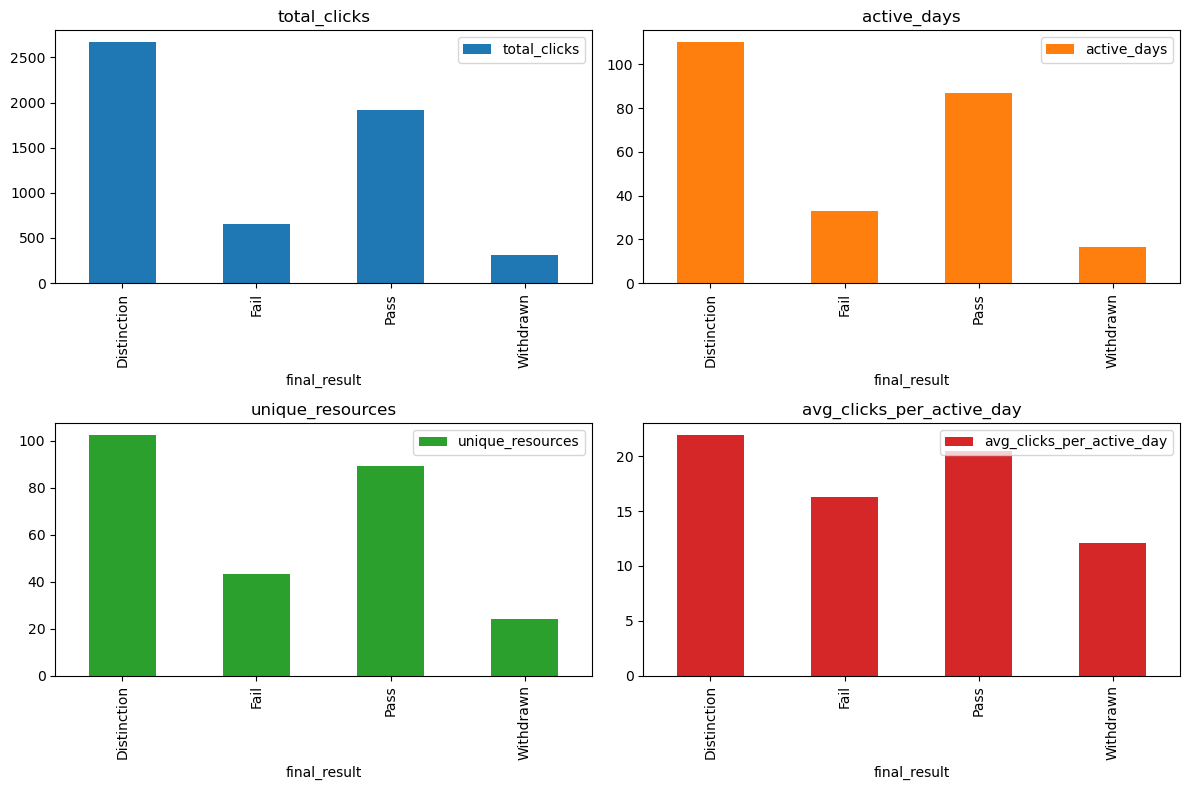

In [16]:
engagement_by_outcome.plot(
    kind="bar",
    subplots=True,
    layout=(2, 2),
    figsize=(12, 8),
    sharex=False
)

plt.tight_layout()
plt.show()

In [17]:
print(df.columns.tolist())

['id_student', 'code_module', 'code_presentation', 'gender', 'age_band', 'imd_band', 'num_of_prev_attempts', 'studied_credits', 'disability', 'final_result', 'total_clicks', 'active_days', 'unique_resources', 'avg_clicks_per_active_day', 'q1_active', 'q2_active', 'q3_active', 'q4_active', 'q1_clicks', 'q2_clicks', 'q3_clicks', 'q4_clicks', 'assessments_completed', 'average_assessment_score', 'early_disengagement']


In [18]:
print(df.shape)

(32593, 25)


In [19]:
df.to_csv(
    "../data/analytical_dataset_clean.csv",
    index=False
)